#### VAR 3-horario de Z (Hs tras la PIT) con cambio de régimen por tipo de tiempo (WT)
z(t) = c_s + Σ φ_{k,s} z(t−k) + σ_s · ε(t),   s = WT en t

- **WT**: k-medias sobre las PCs de presión (6-horarias, sin estacionalidad), en entrenamiento 1985–2015.
- **Régimen observado**: un AR por WT, por mínimos cuadrados (sin EM). Más adelante: estados ocultos (Markov-switching de verdad).
- **Validación 1**: con la secuencia histórica de WT (2016–2025) → cronología, cuantiles, temporales, máximos anuales.
- **Validación 2**: secuencias de WT simuladas con una cadena de Markov estacional → periodos de retorno.

In [1]:
import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from scipy.stats import genextreme
from scipy.signal import find_peaks

In [2]:
import pickle
from utils.pit.piece_wise_marginal import from_normal
from utils.tv_var.harmonic_standardizer import HarmonicStandardizer

waves_df = pd.read_csv("inputs/waves_bulk.csv", index_col=0, parse_dates=True)
tr_ = pickle.load(open("outputs/marginal/transformacion.pkl", "rb"))
marg, harm_z = tr_["marg"], tr_["harm_z"]

def hs_desde_z(z):
    """Serie de Z (Hs) → Hs en metros, deshaciendo la armónica, Φ y la marginal."""
    zz = pd.DataFrame({"VHM0": z, "VTM02": 0.0}, index=z.index)      # la armónica se ajustó con las dos columnas
    z0 = harm_z.inverse_transform(zz)["VHM0"].clip(-6.36, 6.36)    # mismo límite que to_normal (eps=1e-10)
    return pd.Series(marg["VHM0"].ppf(from_normal(z0).values), index=z.index)

In [3]:
#### Z 3-horaria (media de 3 h centrada) y Hs observada
z_bulk = pd.read_csv("outputs/marginal/z_bulk.csv", index_col=0, parse_dates=True)
horas_3h = list(range(0, 24, 3))
z3 = z_bulk["VHM0"].rolling("3h", center=True).mean()
z3 = z3[z3.index.hour.isin(horas_3h)].loc["1985":"2025"].asfreq("3h")
hs_obs = waves_df.loc["1985":"2025", "VHM0"]
print(z3.isna().sum(), len(z3))

0 119800


In [4]:
#### Tipos de tiempo: k-medias sobre las 13 PCs de presión 6-horarias, sin estacionalidad
N_WT = 16                                                   # ← probar 9, 16, 25, 36
pcs_sel = pd.read_csv("outputs/seleccion_6h/pcs_seleccionadas_6h.csv", index_col=0, parse_dates=True)
cols_msl = [c_ for c_ in pcs_sel.columns if c_.startswith("msl")]
harm_pcs = HarmonicStandardizer(n_harmonics=3).fit(pcs_sel[cols_msl])
pcs_wt = harm_pcs.transform(pcs_sel[cols_msl]).loc["1941":"2025"]

km = KMeans(n_clusters=N_WT, n_init=10, random_state=0).fit(pcs_wt.loc["1985":"2015"])
wt_6h = pd.Series(km.predict(pcs_wt), index=pcs_wt.index)
wt = wt_6h.reindex(z3.index, method="ffill")                # WT en la malla 3-horaria
print(wt.value_counts(normalize=True).sort_index().round(3).values)

[0.055 0.067 0.062 0.055 0.075 0.055 0.058 0.071 0.063 0.055 0.076 0.077
 0.066 0.06  0.059 0.047]


In [5]:
#### ¿Separan los WT el oleaje? Z media y q95 por WT (entrenamiento)
d = pd.DataFrame({"z": z3, "wt": wt}).loc["1985":"2015"]
tabla_wt = d.groupby("wt")["z"].agg(["mean", "std", lambda x: x.quantile(0.95)]).round(2)
tabla_wt.columns = ["media Z", "std Z", "q95 Z"]
print(tabla_wt.sort_values("media Z").T.to_string())

wt         7     4     11    1     12    14    0     3     2     5     10    9     6     15    13    8 
media Z -0.65 -0.25 -0.25 -0.24 -0.23 -0.18 -0.11 -0.10 -0.04  0.04  0.10  0.17  0.32  0.55  0.61  0.62
std Z    1.04  0.98  0.94  1.05  0.82  1.03  0.82  1.05  0.95  1.00  0.71  1.03  0.91  0.76  0.79  0.96
q95 Z    1.13  1.37  1.30  1.46  1.09  1.51  1.16  1.62  1.58  1.75  1.25  1.88  1.77  1.76  1.89  2.13


In [6]:
#### Un AR por WT (régimen observado). p en pasos de 3 h
P = 8                                                       # ← 8 × 3 h = 24 h de memoria
def matriz(z, p):
    return pd.concat({f"z{k}": z.shift(k) for k in range(1, p + 1)}, axis=1)

X_all = matriz(z3, P)
tr = slice("1985-01-01", "2015-12-31")
ok = X_all.notna().all(axis=1) & z3.notna()

coefs, sig_wt, pools = {}, {}, {}
for s in range(N_WT):
    m = ok & (wt == s)
    m_tr = m.loc[tr]
    X = np.c_[np.ones(m_tr.sum()), X_all.loc[tr][m_tr].values]
    y = z3.loc[tr][m_tr].values
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    e = y - X @ b
    coefs[s], sig_wt[s], pools[s] = b, e.std(), e                # residuos reales del WT (bootstrap)
print("σ por WT:", np.round([sig_wt[s] for s in range(N_WT)], 3))
print("Σφ por WT:", np.round([coefs[s][1:].sum() for s in range(N_WT)], 3))

σ por WT: [0.162 0.188 0.26  0.218 0.174 0.206 0.216 0.173 0.194 0.17  0.186 0.192
 0.182 0.239 0.202 0.175]
Σφ por WT: [0.95  0.962 0.931 0.95  0.96  0.951 0.942 0.965 0.955 0.965 0.931 0.95
 0.944 0.911 0.956 0.936]


In [7]:
def simular_z(wt_seq, z_ini, rng):
    """Z 3-horaria dirigida por una secuencia de WT; innovaciones remuestreadas del pool de cada WT."""
    n = len(wt_seq)
    z = np.empty(n + P)
    z[:P] = z_ini                                           # orden cronológico
    w = np.asarray(wt_seq)
    for t in range(n):
        b = coefs[w[t]]
        z[t + P] = b[0] + b[1:] @ z[t:t + P][::-1] + pools[w[t]][rng.integers(len(pools[w[t]]))]   # lag 1 primero
    return pd.Series(z[P:], index=wt_seq.index)

#### Validación 1 — con la secuencia histórica de WT (test 2016–2025)

In [8]:
te = slice("2016-01-01", "2025-12-31")
wt_te = wt.loc[te]
z_ini = z3.loc[:"2015-12-31"].values[-P:]                   # últimos P valores, en orden cronológico

import time
n_sims = 50
hs_sims = []
for i in range(n_sims):
    z_i = simular_z(wt_te, z_ini, np.random.default_rng(i))
    hs_sims.append(hs_desde_z(z_i))
hs_sims = pd.concat(hs_sims, axis=1)
hs_te = hs_obs.loc[te]

#### Cronología (diaria) y distribución
med_d = hs_sims.median(axis=1).resample("D").mean()
print(f"corr diaria (mediana sim vs obs): {med_d.corr(hs_te.resample('D').mean()):.3f}   (XGB: 0.81)")
q_lo, q_hi = hs_sims.quantile(0.025, axis=1), hs_sims.quantile(0.975, axis=1)
o = hs_te.reindex(hs_sims.index)
print(f"por encima {(o > q_hi).mean():.1%} | por debajo {(o < q_lo).mean():.1%}  (esperado 2,5 %)")
st = pd.DataFrame({"q99": hs_sims.quantile(0.99), "q999": hs_sims.quantile(0.999), "max": hs_sims.max()})
print(f"obs: q99 {hs_te.quantile(0.99):.2f} | q999 {hs_te.quantile(0.999):.2f} | max {hs_te.max():.2f}")
print(st.quantile([0.025, 0.5, 0.975]).round(2))

corr diaria (mediana sim vs obs): 0.505   (XGB: 0.81)
por encima 3.2% | por debajo 4.5%  (esperado 2,5 %)
obs: q99 2.61 | q999 3.63 | max 5.50
        q99  q999   max
0.025  2.89  4.45  5.73
0.500  3.06  4.85  6.82
0.975  3.32  5.69  8.22


nº temporales: obs 50 | sim 94 [76–107]  (XGB+ruido: 75 vs 60 horario)


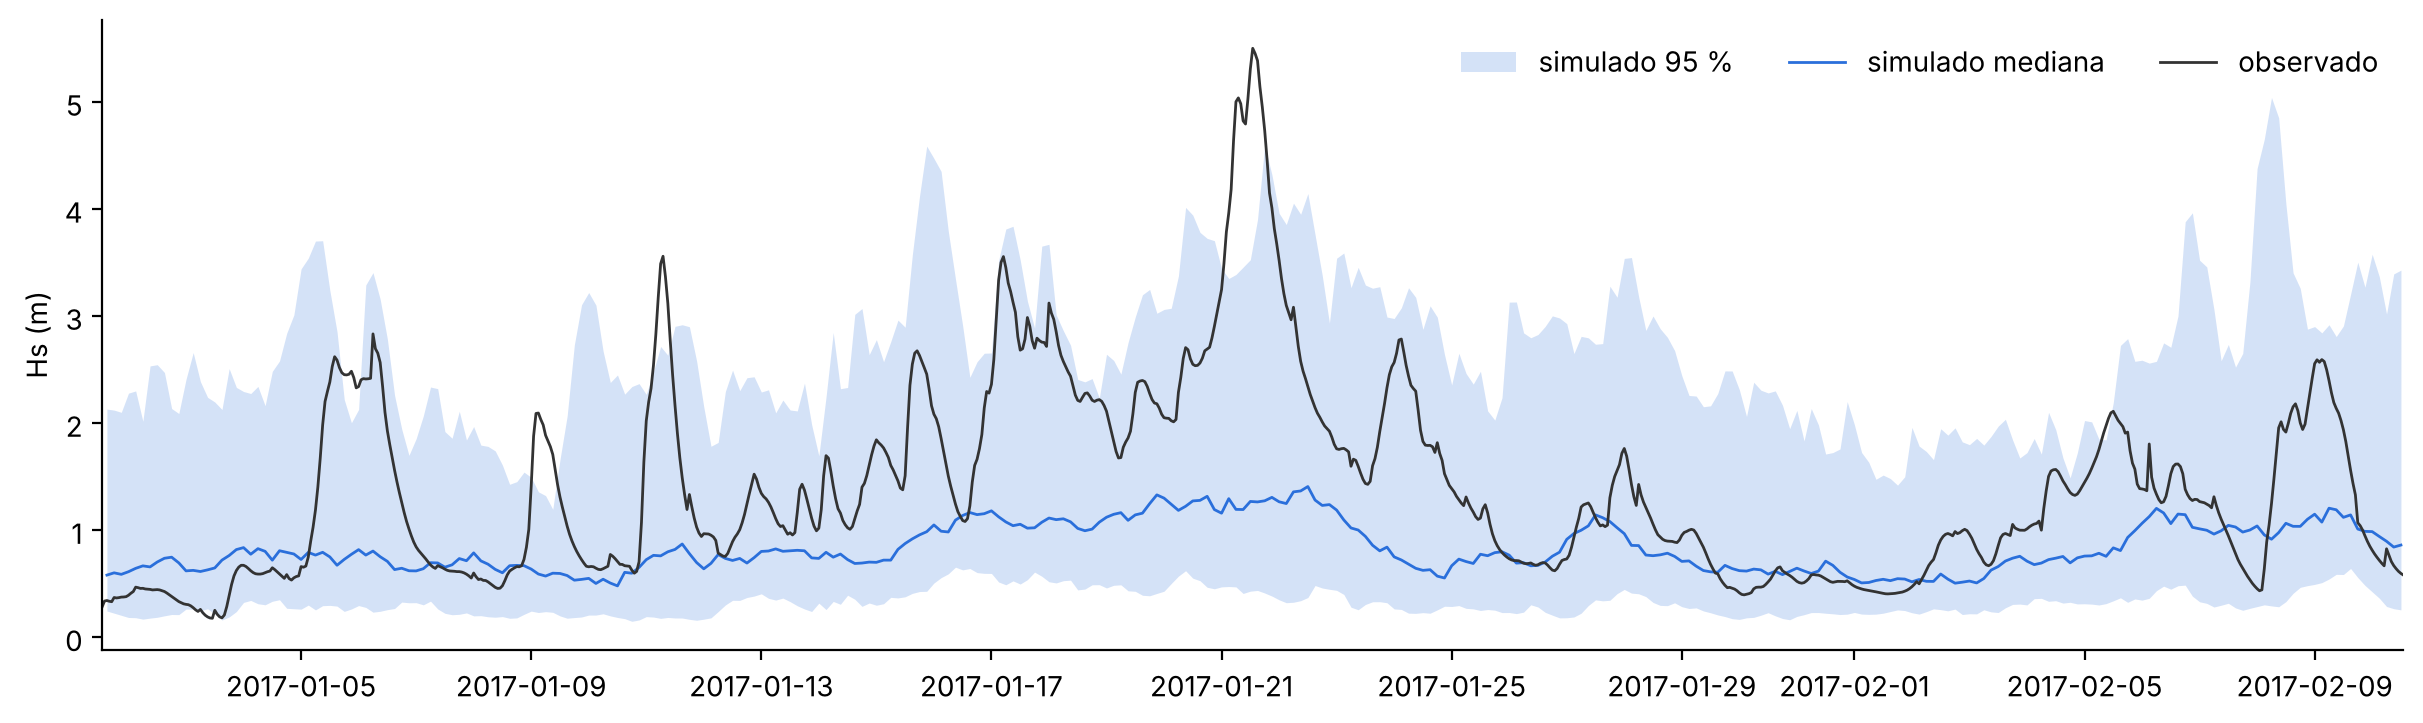

In [9]:
#### Temporales (umbral = q99 observado del test, separados 72 h; en 3 h → distance 24)
u = hs_te.quantile(0.99)
def picos(serie, sep_pasos):
    return serie.iloc[find_peaks(serie.values, height=u, distance=sep_pasos)[0]].values
hs_te_3h = hs_te.rolling("3h", center=True).mean()[hs_te.index.hour.isin(horas_3h)]
p_obs = picos(hs_te_3h, 24)
p_sim = [picos(hs_sims[c_], 24) for c_ in hs_sims.columns]
n_sim = [len(p_) for p_ in p_sim]
print(f"nº temporales: obs {len(p_obs)} | sim {np.median(n_sim):.0f} [{np.percentile(n_sim, 2.5):.0f}–{np.percentile(n_sim, 97.5):.0f}]  (XGB+ruido: 75 vs 60 horario)")

t_max = hs_te.idxmax()
t0, t1 = t_max - pd.Timedelta(days=20), t_max + pd.Timedelta(days=20)
w_ = hs_sims.loc[t0:t1]
fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.fill_between(w_.index, w_.quantile(0.025, axis=1), w_.quantile(0.975, axis=1), color="#2a6fdb", alpha=0.2, lw=0, label="simulado 95 %")
ax.plot(w_.median(axis=1), color="#2a6fdb", lw=1, label="simulado mediana")
ax.plot(hs_te.loc[t0:t1], color="0.2", lw=1, label="observado")
ax.set(ylabel="Hs (m)", xlim=(t0, t1))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right", ncol=3)
plt.show()

#### Validación 2 — secuencias de WT simuladas (cadena de Markov por mes) → periodos de retorno

In [10]:
#### Matriz de transición 3-horaria por mes (entrenamiento)
w_tr = wt.loc[tr].values
mes_tr = wt.loc[tr].index.month.values
T_mes = {}
for m in range(1, 13):
    sel = mes_tr[:-1] == m
    C = np.zeros((N_WT, N_WT))
    np.add.at(C, (w_tr[:-1][sel], w_tr[1:][sel]), 1)
    C += 1e-3                                               # evita filas vacías
    T_mes[m] = C / C.sum(axis=1, keepdims=True)

def simular_wt(fechas, w0, rng):
    w = np.empty(len(fechas), dtype=int)
    w[0] = w0
    meses = fechas.month.values
    for t in range(1, len(fechas)):
        w[t] = rng.choice(N_WT, p=T_mes[meses[t]][w[t - 1]])
    return pd.Series(w, index=fechas)

#### Persistencia: duración media de las rachas de un mismo WT (h), obs vs simulada
def rachas(w):
    cambio = np.r_[True, w.values[1:] != w.values[:-1]]
    return pd.Series(np.diff(np.r_[np.flatnonzero(cambio), len(w)]) * 3).mean()
w_sim0 = simular_wt(wt.loc[tr].index, w_tr[0], np.random.default_rng(0))
print(f"duración media de racha: obs {rachas(wt.loc[tr]):.1f} h | Markov {rachas(w_sim0):.1f} h")

duración media de racha: obs 22.4 h | Markov 22.4 h


In [11]:
#### Simulaciones largas: 20 × 85 años
n_largas, n_anos = 20, 85
fechas = pd.date_range("1941-01-01", periods=n_anos * 2920, freq="3h")
am_sim = []
for i in range(n_largas):
    t = time.time()
    rng = np.random.default_rng(100 + i)
    w_i = simular_wt(fechas, rng.integers(N_WT), rng)
    hs_i = hs_desde_z(simular_z(w_i, z_ini, rng))
    am_sim.append(hs_i.groupby(hs_i.index.year).max().reset_index(drop=True))
    print(f"sim {i:02d} ({time.time() - t:.0f} s)")
am_sim = pd.concat(am_sim, axis=1)
pickle.dump(am_sim, open("outputs/xgb_pit/am_msvar_wt.pkl", "wb"))

sim 00 (2 s)


sim 01 (3 s)


sim 02 (3 s)


sim 03 (2 s)


sim 04 (2 s)


sim 05 (3 s)


... (10 outputs left out)

sim 16 (2 s)


sim 17 (2 s)


sim 18 (2 s)


sim 19 (3 s)


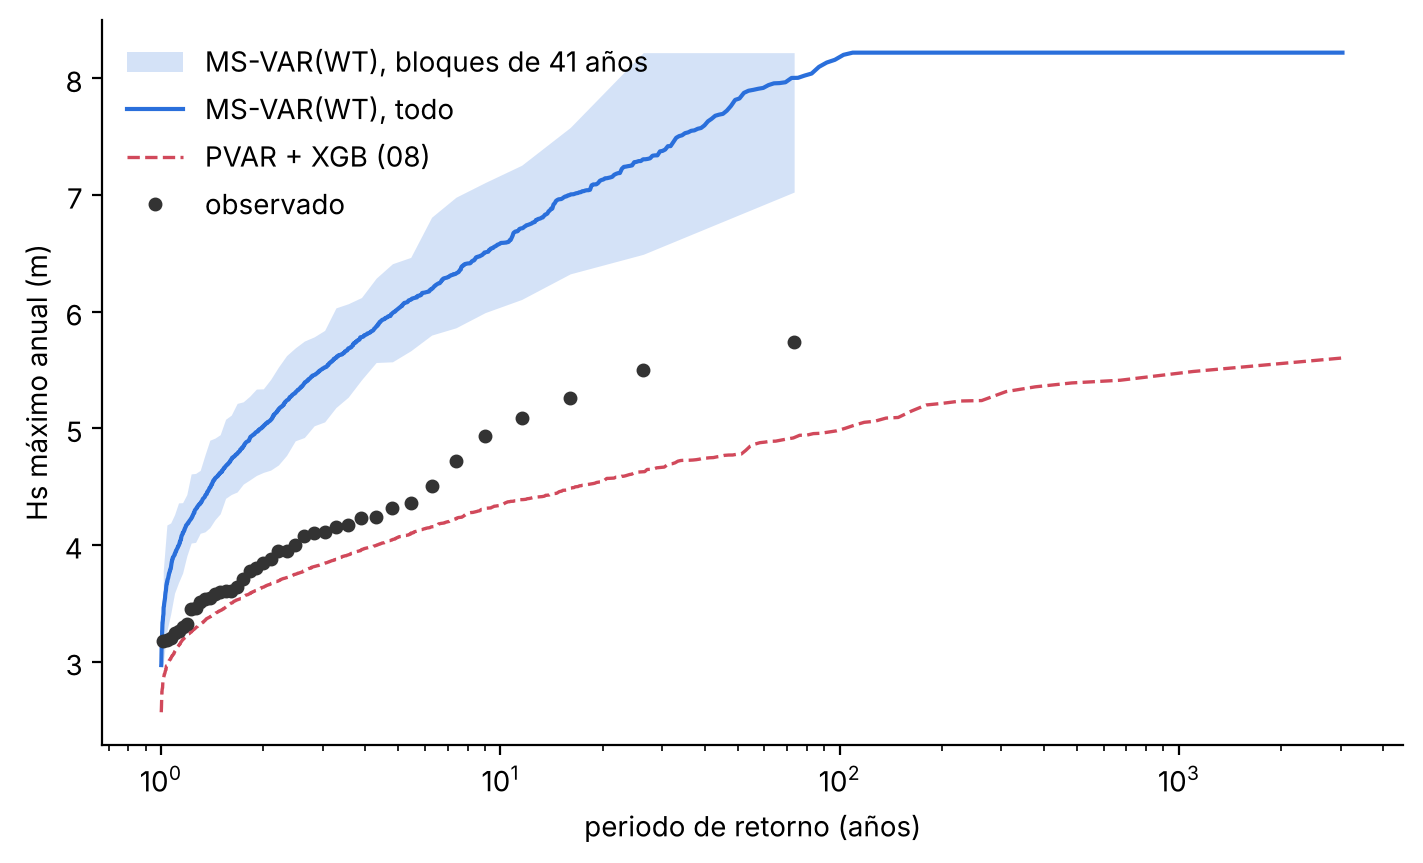

        obs  MS-VAR bloques med    lo    hi
ξ      0.16               -0.09 -0.31  0.16
μ      3.65                4.74  4.43  5.06
σ      0.43                0.87  0.66  1.06
Hs2    3.81                5.03  4.73  5.42
Hs10   4.80                6.48  6.13  6.92
Hs50   5.95                7.61  6.80  8.44
Hs100  6.53                7.99  7.02  9.53
std entre años del máx. anual: obs 0.64 | sim 1.04


In [12]:
#### Periodos de retorno: obs vs MS-VAR(WT), y PVAR/kNN si existen
def gringorten(am):
    am = np.sort(np.asarray(am)); n = len(am)
    return 1 / (1 - (np.arange(1, n + 1) - 0.44) / (n + 0.12)), am

am_obs = hs_obs.groupby(hs_obs.index.year).max()
n_b = len(am_obs)
bloques = [am_sim[c_].values[j:j + n_b] for c_ in am_sim.columns for j in range(0, len(am_sim) - n_b + 1, n_b)]
bo = np.array([np.sort(b) for b in bloques]).T
T_b = gringorten(np.arange(n_b))[0]

fig, ax = plt.subplots(figsize=(7, 4.2), constrained_layout=True)
ax.fill_between(T_b, np.percentile(bo, 2.5, axis=1), np.percentile(bo, 97.5, axis=1), color="#2a6fdb", alpha=0.2, lw=0, label="MS-VAR(WT), bloques de 41 años")
ax.plot(*gringorten(am_sim.values.ravel()), color="#2a6fdb", lw=1.5, label="MS-VAR(WT), todo")
for fic, col, nom in [("outputs/xgb_pit/am_pvar.pkl", "#d1495b", "PVAR + XGB (08)"), ("outputs/xgb_pit/am_knn.pkl", "#3a9e5f", "kNN + XGB (10)")]:
    try:
        ax.plot(*gringorten(pickle.load(open(fic, "rb"))["am_hs"].values.ravel()), color=col, lw=1.2, ls="--", label=nom)
    except FileNotFoundError:
        pass
ax.plot(*gringorten(am_obs), "o", color="0.2", ms=4, label="observado")
ax.set(xscale="log", xlabel="periodo de retorno (años)", ylabel="Hs máximo anual (m)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

def gev(am):
    c_, loc, scale = genextreme.fit(am)
    return {"ξ": -c_, "μ": loc, "σ": scale, **{f"Hs{t}": genextreme.ppf(1 - 1 / t, c_, loc, scale) for t in [2, 10, 50, 100]}}
g_b = pd.DataFrame([gev(b) for b in bloques])
print(pd.DataFrame({"obs": pd.Series(gev(am_obs.values)), "MS-VAR bloques med": g_b.median(),
                    "lo": g_b.quantile(0.025), "hi": g_b.quantile(0.975)}).round(2).to_string())
print(f"std entre años del máx. anual: obs {am_obs.std():.2f} | sim {np.median(am_sim.std()):.2f}")